In [1]:
# importación de librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV, RandomizedSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay, f1_score

In [2]:
#importación de data
df=pd.read_csv("dataset/sintetico_append.csv", sep=";")

In [3]:
# Mostrar dimensiones iniciales
print(f'Dimensiones iniciales del dataset: {df.shape}')

# Eliminar columnas irrelevantes generadas comúnmente al exportar CSVs (como índices sin nombre)
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

Dimensiones iniciales del dataset: (10390, 23)


In [4]:
df.head(5)

,id_estudiante,promedio_previo,asistencia_hist,sin_historial,carga_cursos,veces_llevado_curso,tiempo_traslado,uso_recursos_alternativos,dia_semana,franja,...,dificultad_tema,dias_a_evaluacion,asistio,fold,tipo_franja,plazo_tramo,combinacion,combo_reservada,fase_ciclo,p_asistir
0,sint_0001,1271,48.0,0,3,2,420,4,martes,noche,...,1,1,0,0.0,ocupada,manana,ocupada|manana|1|virtual,0,previo_evaluacion,5044
1,sint_0001,1271,48.0,0,3,2,420,4,jueves,manana,...,3,1,1,0.0,libre,manana,libre|manana|3|virtual,0,previo_evaluacion,9336
2,sint_0001,1271,48.0,0,3,2,420,4,sabado,noche,...,5,1,1,0.0,acomoda,manana,acomoda|manana|5|virtual,0,previo_evaluacion,9925
3,sint_0001,1271,48.0,0,3,2,420,4,martes,tarde,...,3,3,1,0.0,ocupada,3a5dias,ocupada|3a5dias|3|virtual,0,previo_evaluacion,747
4,sint_0001,1271,48.0,0,3,2,420,4,martes,noche,...,2,13,1,0.0,ocupada,2semanas,ocupada|2semanas|2|virtual,0,posterior_evaluacion,6249


In [5]:
# Eliminar columnas que no corresponden a la predicción del modelo
df = df.drop(columns=['id_estudiante', 'fold', 'tipo_franja','plazo_tramo','combinacion','p_asistir','combo_reservada','fase_ciclo'])

### **Preprocesamiento**

In [6]:
# Eliminación de duplicados exactos
df = df.drop_duplicates().copy()  # CAMBIO: eliminar filas idénticas; copy evita vistas ambiguas
print(f'Dimensiones después de eliminar duplicados exactos: {df.shape}')

Dimensiones después de eliminar duplicados exactos: (10375, 15)


In [7]:
print("Valores nulos por columna antes de limpieza:")
display(df.isnull().sum())

Valores nulos por columna antes de limpieza:


promedio_previo                 0
asistencia_hist              1050
sin_historial                   0
carga_cursos                    0
veces_llevado_curso             0
tiempo_traslado                 0
uso_recursos_alternativos       0
dia_semana                      0
franja                          0
cruce_horario                   0
dispuesto_franja                0
modalidad                       0
dificultad_tema                 0
dias_a_evaluacion               0
asistio                         0
dtype: int64

In [8]:
#rellenar los valores nulos de la asistencia con la media de asistencias por cantidad de cursos
df['asistencia_hist'] = df['asistencia_hist'].fillna(
    df.groupby('carga_cursos')['asistencia_hist'].transform('median')
)

In [9]:
print("Valores nulos por columna después de limpieza de limpieza:")
display(df.isnull().sum())

Valores nulos por columna después de limpieza de limpieza:


promedio_previo              0
asistencia_hist              0
sin_historial                0
carga_cursos                 0
veces_llevado_curso          0
tiempo_traslado              0
uso_recursos_alternativos    0
dia_semana                   0
franja                       0
cruce_horario                0
dispuesto_franja             0
modalidad                    0
dificultad_tema              0
dias_a_evaluacion            0
asistio                      0
dtype: int64

In [10]:
# Revisar tipos actuales
print("Tipos de datos originales:")
display(df.dtypes)

Tipos de datos originales:


promedio_previo                int64
asistencia_hist              float64
sin_historial                  int64
carga_cursos                   int64
veces_llevado_curso            int64
tiempo_traslado                int64
uso_recursos_alternativos      int64
dia_semana                       str
franja                           str
cruce_horario                  int64
dispuesto_franja               int64
modalidad                        str
dificultad_tema                int64
dias_a_evaluacion              int64
asistio                        int64
dtype: object

In [11]:
# analisis de target
df['asistio'].value_counts(normalize=True)

asistio
1    0.61012
0    0.38988
Name: proportion, dtype: float64

In [12]:
#arreglar valores de algunas columnas numéricas
df['promedio_previo'] = df['promedio_previo'] / 100
df['asistencia_hist'] = df['asistencia_hist'] / 100
df['tiempo_traslado'] = df['tiempo_traslado'] / 10

In [13]:
#analizar variables numericas
df_numericas = df.select_dtypes('number').copy(deep=True)
df_numericas.head()

,promedio_previo,asistencia_hist,sin_historial,carga_cursos,veces_llevado_curso,tiempo_traslado,uso_recursos_alternativos,cruce_horario,dispuesto_franja,dificultad_tema,dias_a_evaluacion,asistio
0,12.71,0.48,0,3,2,42.0,4,1,0,1,1,0
1,12.71,0.48,0,3,2,42.0,4,0,0,3,1,1
2,12.71,0.48,0,3,2,42.0,4,0,1,5,1,1
3,12.71,0.48,0,3,2,42.0,4,1,0,3,3,1
4,12.71,0.48,0,3,2,42.0,4,1,0,2,13,1


In [14]:
df_numericas.describe()

,promedio_previo,asistencia_hist,sin_historial,carga_cursos,veces_llevado_curso,tiempo_traslado,uso_recursos_alternativos,cruce_horario,dispuesto_franja,dificultad_tema,dias_a_evaluacion,asistio
count,10375.000000,10375.000000,10375.000000,10375.000000,10375.000000,10375.000000,10375.000000,10375.000000,10375.000000,10375.000000,10375.000000,10375.000000
mean,13.460259,0.427558,0.101205,5.170699,1.708434,47.790072,3.564145,0.390361,0.257157,2.944482,12.604819,0.610120
std,5.329643,0.266432,0.301614,1.414237,0.760823,33.857802,0.794420,0.487855,0.437088,1.402098,8.625198,0.487746
min,0.720000,0.000000,0.000000,2.000000,1.000000,6.000000,2.000000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,12.160000,0.170000,0.000000,4.000000,1.000000,20.000000,3.000000,0.000000,0.000000,2.000000,5.000000,0.000000
50%,14.770000,0.420000,0.000000,6.000000,2.000000,39.000000,4.000000,0.000000,0.000000,3.000000,12.000000,1.000000
75%,17.220000,0.660000,0.000000,6.000000,2.000000,66.000000,4.000000,1.000000,1.000000,4.000000,20.000000,1.000000
max,19.990000,0.950000,1.000000,7.000000,3.000000,178.000000,5.000000,1.000000,1.000000,5.000000,30.000000,1.000000


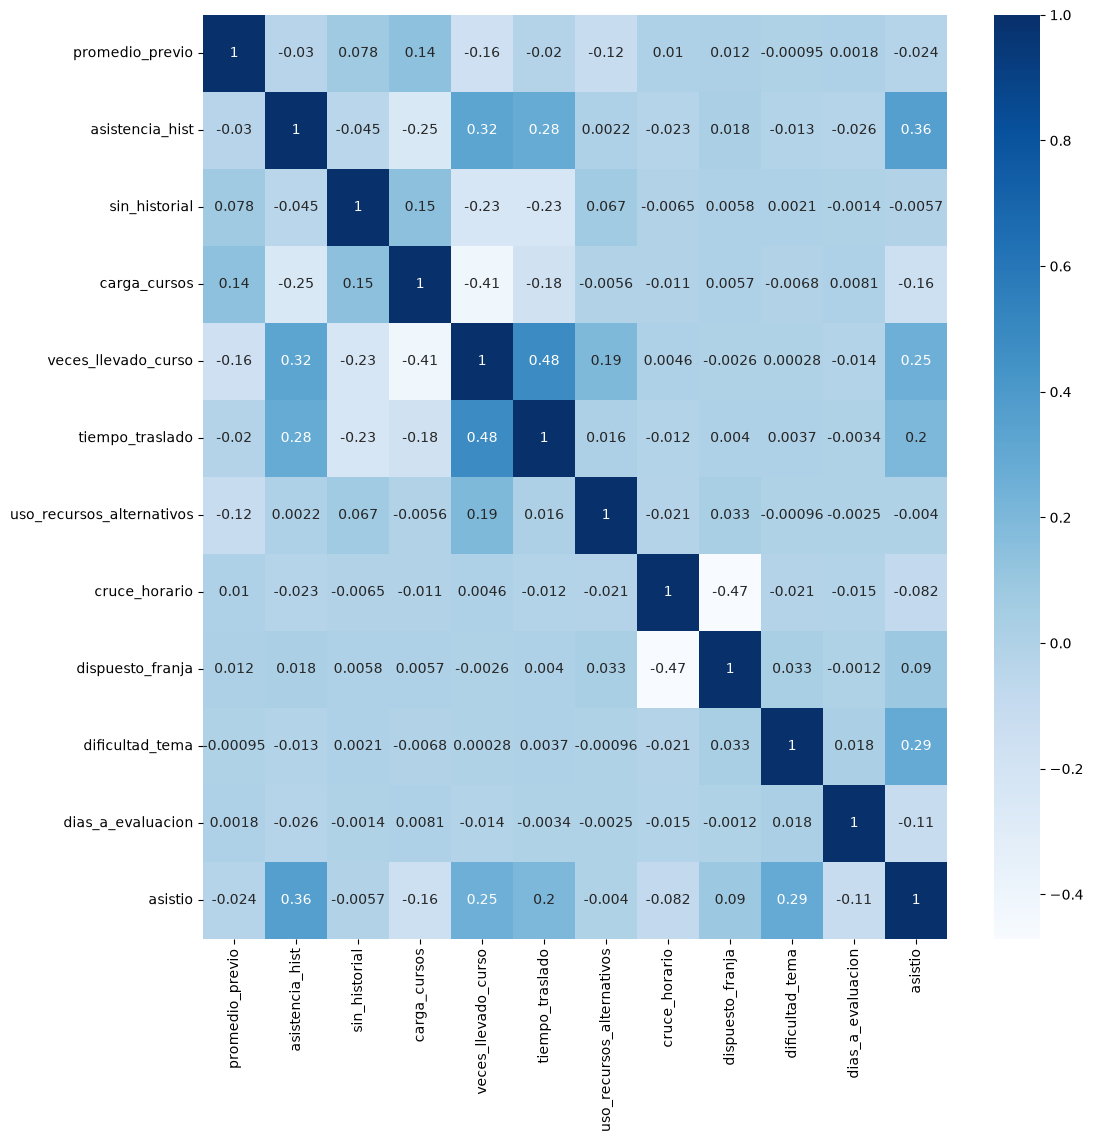

In [15]:
#identificar correlacion
import seaborn as sns
plt.figure(figsize=(12, 12))
df_corr = df_numericas.corr()
sns.heatmap(df_corr, annot=True, cmap='Blues')
plt.show()

In [16]:
df_cat = df.select_dtypes('str').copy(deep=True)
df_cat.head()

,dia_semana,franja,modalidad
0,martes,noche,virtual
1,jueves,manana,virtual
2,sabado,noche,virtual
3,martes,tarde,virtual
4,martes,noche,virtual


In [17]:
# realizar un one hot encoding en las variables categoricas
df_cat.nunique()

dia_semana    6
franja        3
modalidad     2
dtype: int64

In [18]:
df_cat = pd.get_dummies(df_cat, drop_first = True, dtype=int)
df_cat.head()

,dia_semana_lunes,dia_semana_martes,dia_semana_miercoles,dia_semana_sabado,dia_semana_viernes,franja_noche,franja_tarde,modalidad_virtual
0,0,1,0,0,0,1,0,1
1,0,0,0,0,0,0,0,1
2,0,0,0,1,0,1,0,1
3,0,1,0,0,0,0,1,1
4,0,1,0,0,0,1,0,1


In [19]:
# data final preprocesada
# Unimos empleando un merge (simil a left join con los índices como llaves)
df_final = df_numericas.merge(df_cat, how = 'left', left_index = True, right_index = True)
df_final.head()

,promedio_previo,asistencia_hist,sin_historial,carga_cursos,veces_llevado_curso,tiempo_traslado,uso_recursos_alternativos,cruce_horario,dispuesto_franja,dificultad_tema,dias_a_evaluacion,asistio,dia_semana_lunes,dia_semana_martes,dia_semana_miercoles,dia_semana_sabado,dia_semana_viernes,franja_noche,franja_tarde,modalidad_virtual
0,12.71,0.48,0,3,2,42.0,4,1,0,1,1,0,0,1,0,0,0,1,0,1
1,12.71,0.48,0,3,2,42.0,4,0,0,3,1,1,0,0,0,0,0,0,0,1
2,12.71,0.48,0,3,2,42.0,4,0,1,5,1,1,0,0,0,1,0,1,0,1
3,12.71,0.48,0,3,2,42.0,4,1,0,3,3,1,0,1,0,0,0,0,1,1
4,12.71,0.48,0,3,2,42.0,4,1,0,2,13,1,0,1,0,0,0,1,0,1


### **Seleccion de Modelos**

In [20]:
X=df_final.copy(deep = True)
y = X.pop('asistio')

In [21]:
#division en train y test
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

In [22]:
#division en train y validation test
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.2, random_state=30, stratify = y_dev)

In [23]:
# estandarización para clasificacion
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
scaler.fit(X_train)
X_train_sc = scaler.transform(X_train)
X_val_sc = scaler.transform(X_val)
X_test_sc = scaler.transform(X_test)

In [24]:
#definicion de modelos a usar
lr = LogisticRegression()
dt = DecisionTreeClassifier()
knn = KNeighborsClassifier(n_neighbors=5) # probaremos con un k=5
rt= RandomForestClassifier()

lr.fit(X_train_sc, y_train)
dt.fit(X_train_sc, y_train)
knn.fit(X_train_sc, y_train)
rt.fit(X_train_sc, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [25]:
## estimar prediccion con validation
y_pred_lr = lr.predict(X_val_sc)
y_pred_dt = dt.predict(X_val_sc)
y_pred_knn = knn.predict(X_val_sc)
y_pred_rt = rt.predict(X_val_sc)

In [26]:
##estimacion con probabilidad
y_proba_lr = lr.predict_proba(X_val_sc)
y_proba_dt = dt.predict_proba(X_val_sc)
y_proba_knn = knn.predict_proba(X_val_sc)
y_proba_rt = rt.predict_proba(X_val_sc)

In [27]:
y_proba_lr[:10]

array([[0.65030984, 0.34969016],
       [0.25590792, 0.74409208],
       [0.21538429, 0.78461571],
       [0.2615294 , 0.7384706 ],
       [0.00693926, 0.99306074],
       [0.44925533, 0.55074467],
       [0.23886905, 0.76113095],
       [0.71548162, 0.28451838],
       [0.20752228, 0.79247772],
       [0.12585845, 0.87414155]])

In [28]:
# medicion de acurracy
print(f"Acc. LR = {accuracy_score(y_val, y_pred_lr)}")
print(f"Acc. DT = {accuracy_score(y_val, y_pred_dt)}")
print(f"Acc. KNN = {accuracy_score(y_val, y_pred_knn)}")
print(f"Acc. RT = {accuracy_score(y_val, y_pred_rt)}")

Acc. LR = 0.772289156626506
Acc. DT = 0.6975903614457831
Acc. KNN = 0.6939759036144578
Acc. RT = 0.7783132530120482


In [29]:
# medicion de precision

from sklearn.metrics import precision_score

print(f"Pr. LR = {precision_score(y_val, y_pred_lr)}")
print(f"Pr. DT = {precision_score(y_val, y_pred_dt)}")
print(f"Pr. KNN = {precision_score(y_val, y_pred_knn)}")
print(f"Pr. RT = {precision_score(y_val, y_pred_rt)}")

Pr. LR = 0.7958993476234856
Pr. DT = 0.7609805924412666
Pr. KNN = 0.7407054337464252
Pr. RT = 0.8097982708933718


In [30]:
# medicion de recall

from sklearn.metrics import recall_score

print(f"Rec. LR = {recall_score(y_val, y_pred_lr)}")
print(f"Rec. DT = {recall_score(y_val, y_pred_dt)}")
print(f"Rec. KNN = {recall_score(y_val, y_pred_knn)}")
print(f"Rec. RT = {recall_score(y_val, y_pred_rt)}")

Rec. LR = 0.843040473840079
Rec. DT = 0.7354392892398816
Rec. KNN = 0.7670286278381047
Rec. RT = 0.8321816386969397


In [31]:
#medicion de f1_score
print(f"F1. LR = {f1_score(y_val, y_pred_lr)}")
print(f"F1. DT = {f1_score(y_val, y_pred_dt)}")
print(f"F1. KNN = {f1_score(y_val, y_pred_knn)}")
print(f"F1. RT = {f1_score(y_val, y_pred_rt)}")

F1. LR = 0.8187919463087249
F1. DT = 0.7479919678714859
F1. KNN = 0.7536372453928225
F1. RT = 0.8208373904576436


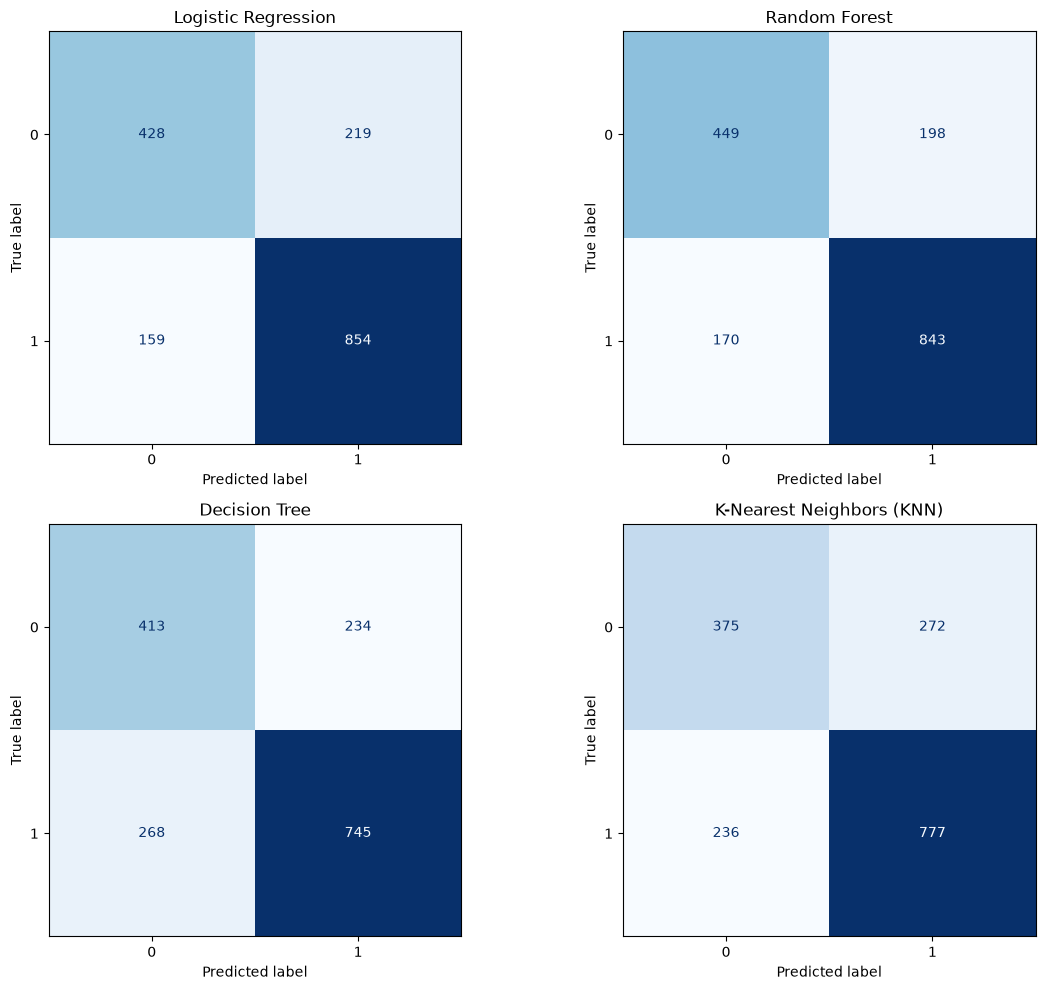

In [32]:
#matriz de confusion de cada modelo
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

labels = df[
    'asistio'
].unique()  

# --- Modelo 1: Logistic Regression ---
cm_lr = confusion_matrix(y_val, y_pred_lr)
disp_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr, display_labels=labels
)
disp_lr.plot(
    ax=axes[0, 0], cmap=plt.cm.Blues, colorbar=False
)  # Usamos ax=axes[0,0]
axes[0, 0].set_title('Logistic Regression')

# --- Modelo 2: Random Forest ---
cm_rf = confusion_matrix(y_val, y_pred_rt)
disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf, display_labels=labels
)
disp_rf.plot(ax=axes[0, 1], cmap=plt.cm.Blues, colorbar=False)
axes[0, 1].set_title('Random Forest')

# --- Modelo 3: Decision Tree ---
cm_dt = confusion_matrix(y_val, y_pred_dt)
disp_dt = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt, display_labels=labels
)
disp_dt.plot(ax=axes[1, 0], cmap=plt.cm.Blues, colorbar=False)
axes[1, 0].set_title('Decision Tree')

# --- Modelo 4: KNN ---
cm_knn = confusion_matrix(y_val, y_pred_knn)
disp_knn = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn, display_labels=labels
)
disp_knn.plot(ax=axes[1, 1], cmap=plt.cm.Blues, colorbar=False)
axes[1, 1].set_title('K-Nearest Neighbors (KNN)')

# Ajustar el diseño para que no se encimen los textos y mostrar
plt.tight_layout()
plt.show()

### **K fold validation**

In [46]:
from sklearn.pipeline import Pipeline

# Creamos un pipeline que escale y luego ejecute el modelo
pipeline_lr = Pipeline([('scaler', MinMaxScaler()), ('lr', LogisticRegression())])
pipeline_dt = Pipeline([('scaler', MinMaxScaler()), ('dt', DecisionTreeClassifier())])
pipeline_knn = Pipeline([('scaler', MinMaxScaler()), ('knn', KNeighborsClassifier(n_neighbors=5))])
pipeline_rt = Pipeline([('scaler', MinMaxScaler()), ('rt', RandomForestClassifier())])

In [47]:
#medicion de acurracy
from sklearn.model_selection import cross_val_score

scores_lr = cross_val_score(pipeline_lr, X, y, cv=5, scoring='accuracy')
scores_dt = cross_val_score(pipeline_dt, X, y, cv=5, scoring='accuracy')
scores_knn = cross_val_score(pipeline_knn, X, y, cv=5, scoring='accuracy')
scores_rt = cross_val_score(pipeline_rt, X, y, cv=5, scoring='accuracy')

print(f"Score LR: {scores_lr.mean()} +/- {scores_lr.std()}")
print(f"Score DT: {scores_dt.mean()} +/- {scores_dt.std()}")
print(f"Score KNN: {scores_knn.mean()} +/- {scores_knn.std()}")
print(f"Score RT: {scores_rt.mean()} +/- {scores_rt.std()}")

Score LR: 0.7604819277108434 +/- 0.0046823933692495745
Score DT: 0.6702650602409638 +/- 0.007462258062976743
Score KNN: 0.6932048192771084 +/- 0.00617620022885816
Score RT: 0.7479518072289156 +/- 0.006179207874631187


In [48]:
#medicion de precision
from sklearn.model_selection import cross_val_score

scores_lr = cross_val_score(pipeline_lr, X, y, cv=5, scoring='precision')
scores_dt = cross_val_score(pipeline_dt, X, y, cv=5, scoring='precision')
scores_knn = cross_val_score(pipeline_knn, X, y, cv=5, scoring='precision')
scores_rt = cross_val_score(pipeline_rt, X, y, cv=5, scoring='precision')

print(f"Score LR: {scores_lr.mean()} +/- {scores_lr.std()}")
print(f"Score DT: {scores_dt.mean()} +/- {scores_dt.std()}")
print(f"Score KNN: {scores_knn.mean()} +/- {scores_knn.std()}")
print(f"Score RT: {scores_rt.mean()} +/- {scores_rt.std()}")

Score LR: 0.786387330946303 +/- 0.012826076585408954
Score DT: 0.7292832827905428 +/- 0.007567163633415048
Score KNN: 0.738081420313956 +/- 0.010856755846434503
Score RT: 0.778781813478197 +/- 0.013403997733396162


In [49]:
#medicion de recall
from sklearn.model_selection import cross_val_score

scores_lr = cross_val_score(pipeline_lr, X, y, cv=5, scoring='recall')
scores_dt = cross_val_score(pipeline_dt, X, y, cv=5, scoring='recall')
scores_knn = cross_val_score(pipeline_knn, X, y, cv=5, scoring='recall')
scores_rt = cross_val_score(pipeline_rt, X, y, cv=5, scoring='recall')

print(f"Score LR: {scores_lr.mean()} +/- {scores_lr.std()}")
print(f"Score DT: {scores_dt.mean()} +/- {scores_dt.std()}")
print(f"Score KNN: {scores_knn.mean()} +/- {scores_knn.std()}")
print(f"Score RT: {scores_rt.mean()} +/- {scores_rt.std()}")

Score LR: 0.8347551342812007 +/- 0.016051672411855324
Score DT: 0.721958925750395 +/- 0.015478608169245973
Score KNN: 0.7712480252764613 +/- 0.011539957262401071
Score RT: 0.823222748815166 +/- 0.014525376952887957


In [50]:
#medicion de f1
from sklearn.model_selection import cross_val_score

scores_lr = cross_val_score(pipeline_lr, X, y, cv=5, scoring='f1')
scores_dt = cross_val_score(pipeline_dt, X, y, cv=5, scoring='f1')
scores_knn = cross_val_score(pipeline_knn, X, y, cv=5, scoring='f1')
scores_rt = cross_val_score(pipeline_rt, X, y, cv=5, scoring='f1')

print(f"Score LR: {scores_lr.mean()} +/- {scores_lr.std()}")
print(f"Score DT: {scores_dt.mean()} +/- {scores_dt.std()}")
print(f"Score KNN: {scores_knn.mean()} +/- {scores_knn.std()}")
print(f"Score RT: {scores_rt.mean()} +/- {scores_rt.std()}")

Score LR: 0.8096042716985554 +/- 0.0030331798095780843
Score DT: 0.7229619118870036 +/- 0.009355002034777531
Score KNN: 0.7541506192678269 +/- 0.0035630560862554422
Score RT: 0.8001307429495818 +/- 0.0029580300108972297
